<a href="https://colab.research.google.com/github/polepellynithishreddy/CALCULATOR/blob/main/NITHISH_H1N1_Vaccine_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# H1N1 Vaccine Acceptance Prediction & Cost-Optimisation Hackathon

**Team:** LTeamHackathon  
**Notebook purpose:** Complete, reproducible analysis of Dataset B, including data checks, exploratory analysis, preprocessing, model comparison, validation, interpretation, cost scenarios and a testing-set prediction file.

> **Important scope note:** Dataset B's supplied target is `h1n1_vaccine` (whether a respondent received/accepted the H1N1 vaccine). The supplied files do **not** contain a hospitalisation outcome or an observed individual hospitalisation probability. Therefore, this notebook can predict vaccine acceptance, but it cannot honestly train or validate a hospitalisation-risk model. The cost section states the assumptions and provides transparent scenario calculations instead of inventing hospitalisation probabilities.

Run the notebook from top to bottom. Keep the CSV files in the same folder as this notebook, or upload them when prompted in Google Colab.

## Team and responsibilities

Fill in names and GitHub usernames before submission. Suggested division for an 8–9 person team:

| Role | Main responsibility | Name / GitHub |
|---|---|---|
| Team lead / presenter | Coordinate work, explain objective and findings | To be completed |
| Git person | Version control, merges and final notebook | To be completed |
| Data cleaning | Missing values, duplicates, data types and validation | To be completed |
| Exploratory analysis | Descriptive statistics and visualisations | To be completed |
| Modelling | Train and compare classification models | To be completed |
| Visualisation | Charts, confusion matrix, ROC and feature importance | To be completed |
| Testing / evaluation | Validation metrics, threshold and leakage checks | To be completed |
| Slides / write-up | Communicate results, limitations and recommendations | To be completed |
| Reviewer (optional) | Re-run notebook and check reproducibility | To be completed |

## 1. Understand the supplied files and the task

### Files used for the main analysis
- `dataset_B_training.csv`: 4,756 labelled respondents; **29 predictor features**, plus `respondent_id` and target `h1n1_vaccine` (31 columns total).
- `dataset_B_testing.csv`: 4,749 respondents; the same **29 predictor features** plus `respondent_id` (30 columns total), with no target.
- `Dataset B Information`: the task description used for the Dataset B variable definitions and the supplied costs.
- `Dataset A Information.pdf` and `dataset_A_example_submission.csv`, if present, describe a separate Dataset A / `seasonal_vaccine` task. They are not the Dataset B specification and must not be used to determine the Dataset B target or final submission schema.
- `hackathon_notebook.ipynb`: the original generic draft. This completed notebook replaces its placeholder example with the supplied H1N1 data.

**Counting note:** the pasted Dataset B Information text says “30 features”, but its numbered list contains 29 named predictors. The supplied CSVs confirm the structure: 31 training columns = ID + 29 predictors + target; 30 testing columns = ID + 29 predictors. This notebook follows the actual supplied CSV column structure.

### Main prediction objective
Predict the probability that each Dataset B testing respondent has `h1n1_vaccine = 1`. The testing file contains no target labels, so its true performance cannot be calculated here. We use a stratified hold-out validation split from the training data to compare models before refitting the selected model on all labelled rows.

### Cost information transcribed from the supplied Dataset B task description
- H1N1 vaccine cost: **$500** per dose.
- Hospitalisation for H1N1 flu: **$25,000** per hospitalisation.

The supplied target measures vaccine uptake, not infection or hospitalisation. The cost analysis therefore uses transparent break-even and hypothetical scenarios; it does not claim that Dataset B trains an individual hospitalisation-risk model. See Section 13 for the distinction between task-sheet facts and optional scenario assumptions.


## 2. Dataset B variable dictionary

The first column, `respondent_id`, is a unique and random identifier. It is retained for matching predictions to respondents but excluded from model features. The CSV files contain **29 predictor variables** (the task text's statement “remaining 30 features” appears to be a counting inconsistency).

| Feature | Meaning / coding |
|---|---|
| `h1n1_concern` | Concern: 0 not at all, 1 not very, 2 somewhat, 3 very concerned |
| `h1n1_knowledge` | Knowledge: 0 no knowledge, 1 a little knowledge, 2 a lot of knowledge |
| `behavioral_antiviral_meds` | Has taken antiviral medication (0 No, 1 Yes) |
| `behavioral_avoidance` | Avoided close contact with people with flu-like symptoms (0 No, 1 Yes) |
| `behavioral_face_mask` | Has bought a face mask (0 No, 1 Yes) |
| `behavioral_wash_hands` | Frequently washed hands or used hand sanitiser (0 No, 1 Yes) |
| `behavioral_large_gatherings` | Reduced time at large gatherings (0 No, 1 Yes) |
| `behavioral_outside_home` | Reduced contact with people outside own household (0 No, 1 Yes) |
| `behavioral_touch_face` | Avoided touching eyes, nose or mouth (0 No, 1 Yes) |
| `doctor_recc_h1n1` | H1N1 vaccine was recommended by a doctor (0 No, 1 Yes) |
| `child_under_6_months` | Has regular close contact with a child under six months (0 No, 1 Yes) |
| `health_worker` | Is a healthcare worker (0 No, 1 Yes) |
| `health_insurance` | Has health insurance (0 No, 1 Yes) |
| `opinion_h1n1_vacc_effective` | Vaccine effectiveness opinion: 1 not at all effective, 2 not very effective, 3 don't know, 4 somewhat effective, 5 very effective |
| `opinion_h1n1_risk` | Opinion about risk of getting H1N1 without vaccine: 1 very low, 2 somewhat low, 3 don't know, 4 somewhat high, 5 very high |
| `opinion_h1n1_sick_from_vacc` | Worry about getting sick from vaccine: 1 not at all worried, 2 not very worried, 3 don't know, 4 somewhat worried, 5 very worried |
| `age_group` | Age group of respondent |
| `education` | Self-reported education level |
| `race` | Race of respondent |
| `sex` | Sex of respondent |
| `income_poverty` | Household annual income relative to 2008 Census poverty thresholds |
| `marital_status` | Marital status |
| `rent_or_own` | Housing situation |
| `employment_status` | Employment status |
| `census_msa` | Residence within a metropolitan statistical area (MSA), as defined by the U.S. Census |
| `household_adults` | Number of other adults in household, top-coded to 3 |
| `household_children` | Number of children in household, top-coded to 3 |
| `employment_sector` | Industry in which respondent is employed |
| `number_chronic_med_conditions` | Count of chronic conditions from the list in the Dataset B Information text: asthma/other lung condition, diabetes, heart condition, kidney condition, sickle cell/other anaemia, neurological/neuromuscular condition, liver condition, or weakened immune system due to chronic illness/medication |

For binary variables, 0 = No and 1 = Yes. The concern, knowledge and vaccine-opinion fields are **ordered categorical responses**: their numeric codes express order, not equal measured distances. In this notebook they remain numeric inputs for the existing models, so scaling in the logistic-regression pipeline is a modelling transformation, not a claim that the response scale is continuous. Missing values are handled inside the preprocessing pipeline, fitted on the training split only.


## 3. Environment and reproducibility
The notebook uses common Python data-science libraries and scikit-learn. No external download is required.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
print("Libraries loaded. Random seed:", RANDOM_STATE)

Libraries loaded. Random seed: 42


## 4. Load the supplied files

The loader first checks the notebook's current folder and `/mnt/data` (the uploaded-file environment). If the files are not found, it offers a Google Colab upload option. In a local Jupyter session, place both CSV files next to this notebook.

In [2]:
def locate_or_upload(filename):
    candidates = [filename, os.path.join("/mnt/data", filename)]
    for path in candidates:
        if os.path.exists(path):
            print(f"Loaded: {path}")
            return path
    # Google Colab upload fallback
    try:
        from google.colab import files
        print(f"Please upload {filename}")
        uploaded = files.upload()
        if filename in uploaded:
            return filename
    except Exception:
        pass
    raise FileNotFoundError(
        f"Could not find {filename}. Put it beside this notebook or upload it in Google Colab."
    )

TRAIN_FILE = locate_or_upload("dataset_B_training.csv")
TEST_FILE = locate_or_upload("dataset_B_testing.csv")

train_raw = pd.read_csv(TRAIN_FILE)
test_raw = pd.read_csv(TEST_FILE)

print("Training shape:", train_raw.shape)
print("Testing shape:", test_raw.shape)
display(train_raw.head())

Please upload dataset_B_training.csv


Saving dataset_B_testing.csv to dataset_B_testing.csv
Saving dataset_B_training.csv to dataset_B_training.csv
Loaded: dataset_B_testing.csv
Training shape: (4756, 31)
Testing shape: (4749, 30)


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,doctor_recc_h1n1,child_under_6_months,health_worker,health_insurance,opinion_h1n1_vacc_effective,opinion_h1n1_risk,opinion_h1n1_sick_from_vacc,age_group,education,race,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,4.0,4.0,1.0,45 - 54 Years,Some College,White,Female,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,3.0,1.0,2.0,18 - 34 Years,Some College,White,Female,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,NaN,0.0,0.0,1.0,3.0,4.0,2.0,45 - 54 Years,College Graduate,White,Female,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,2.0,1.0,4.0,18 - 34 Years,College Graduate,White,Female,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0
4,5,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,2.0,2.0,1.0,18 - 34 Years,< 12 Years,White,Female,NaN,Not Married,NaN,Unemployed,Non-MSA,3.0,0.0,NaN,0,0


## 5. Initial data validation

Check dimensions, column names, data types, target availability, ID uniqueness and duplicate rows. This step catches common submission errors before modelling.

In [3]:
TARGET = "h1n1_vaccine"
ID_COL = "respondent_id"

assert TARGET in train_raw.columns, f"Training data must contain {TARGET}"
assert TARGET not in test_raw.columns, "Testing data should not contain the target"
assert ID_COL in train_raw.columns and ID_COL in test_raw.columns
assert set(test_raw.columns) == set(train_raw.columns) - {TARGET}, "Train/test feature columns do not match"

# Dataset B structure: ID + 29 predictors + target in training; ID + 29 predictors in testing.
assert train_raw.shape[1] == 31, f"Expected 31 training columns; found {train_raw.shape[1]}"
assert test_raw.shape[1] == 30, f"Expected 30 testing columns; found {test_raw.shape[1]}"
assert train_raw.columns[0] == ID_COL and test_raw.columns[0] == ID_COL
assert train_raw[ID_COL].is_unique, "Training respondent_id values should be unique"
assert test_raw[ID_COL].is_unique, "Testing respondent_id values should be unique"

# Confirm the target is binary (excluding missing values, which are not expected for labels).
target_values = set(train_raw[TARGET].dropna().unique())
assert target_values.issubset({0, 1}), f"Unexpected target values: {target_values}"

# Validate the response scales explicitly described in Dataset B Information.
documented_ranges = {
    "h1n1_concern": {0, 1, 2, 3},
    "h1n1_knowledge": {0, 1, 2},
    "opinion_h1n1_vacc_effective": {1, 2, 3, 4, 5},
    "opinion_h1n1_risk": {1, 2, 3, 4, 5},
    "opinion_h1n1_sick_from_vacc": {1, 2, 3, 4, 5},
}
binary_features = [
    "behavioral_antiviral_meds", "behavioral_avoidance", "behavioral_face_mask",
    "behavioral_wash_hands", "behavioral_large_gatherings", "behavioral_outside_home",
    "behavioral_touch_face", "doctor_recc_h1n1", "child_under_6_months",
    "health_worker", "health_insurance"
]
for col, allowed in documented_ranges.items():
    observed = set(train_raw[col].dropna().unique())
    assert observed.issubset(allowed), f"{col} has undocumented values: {observed - allowed}"
    observed_test = set(test_raw[col].dropna().unique())
    assert observed_test.issubset(allowed), f"Testing {col} has undocumented values: {observed_test - allowed}"
for col in binary_features:
    observed = set(train_raw[col].dropna().unique())
    assert observed.issubset({0, 1}), f"{col} should be binary; found {observed}"
    observed_test = set(test_raw[col].dropna().unique())
    assert observed_test.issubset({0, 1}), f"Testing {col} should be binary; found {observed_test}"

print("Training rows/columns:", train_raw.shape)
print("Testing rows/columns:", test_raw.shape)
print("Training predictor count (excluding ID and target):", train_raw.shape[1] - 2)
print("Testing predictor count (excluding ID):", test_raw.shape[1] - 1)
print("Unique training IDs:", train_raw[ID_COL].nunique(), "/", len(train_raw))
print("Unique testing IDs:", test_raw[ID_COL].nunique(), "/", len(test_raw))
print("Duplicate training rows:", train_raw.duplicated().sum())
print("Duplicate testing rows:", test_raw.duplicated().sum())
print("\nTraining data types:")
display(train_raw.dtypes.rename("dtype").to_frame())
print("\nTarget values:")
display(train_raw[TARGET].value_counts(dropna=False).sort_index().rename("count").to_frame())
print("\nDocumented category-range and binary checks passed.")


Training rows/columns: (4756, 31)
Testing rows/columns: (4749, 30)
Training predictor count (excluding ID and target): 29
Testing predictor count (excluding ID): 29
Unique training IDs: 4756 / 4756
Unique testing IDs: 4749 / 4749
Duplicate training rows: 0
Duplicate testing rows: 0

Training data types:


,dtype
respondent_id,int64
h1n1_concern,float64
h1n1_knowledge,float64
behavioral_antiviral_meds,float64
behavioral_avoidance,float64
behavioral_face_mask,float64
behavioral_wash_hands,float64
behavioral_large_gatherings,float64
behavioral_outside_home,float64
behavioral_touch_face,float64



Target values:


,count
h1n1_vaccine,
0,2882
1,1874



Documented category-range and binary checks passed.


## 6. Data quality and missing-value analysis

Missing values are not automatically evidence of a negative answer. We report them first. Numeric variables will be median-imputed and categorical variables will be most-frequent-imputed within a scikit-learn pipeline. This avoids using validation information to calculate imputation values.

,missing_count,missing_percent
employment_sector,2364,49.71
health_insurance,1925,40.48
income_poverty,712,14.97
doctor_recc_h1n1,319,6.71
rent_or_own,315,6.62
employment_status,235,4.94
marital_status,226,4.75
education,224,4.71
child_under_6_months,134,2.82
health_worker,131,2.75


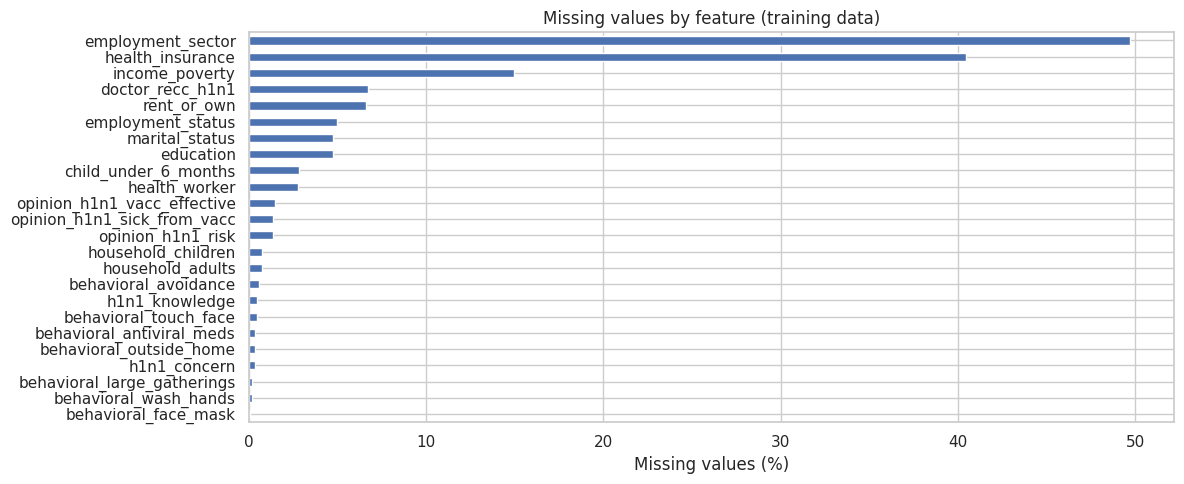

In [4]:
missing = train_raw.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(train_raw) * 100).round(2)
missing_table = pd.DataFrame({"missing_count": missing, "missing_percent": missing_pct})
display(missing_table[missing_table["missing_count"] > 0])

plt.figure(figsize=(12, 5))
missing_table.loc[missing_table.missing_count > 0, "missing_percent"].sort_values().plot(kind="barh")
plt.title("Missing values by feature (training data)")
plt.xlabel("Missing values (%)")
plt.tight_layout()
plt.show()

## 7. Exploratory data analysis (EDA)

### 7.1 Target distribution
The target is binary: 0 = no H1N1 vaccine, 1 = H1N1 vaccine. Class balance matters because accuracy alone can be misleading when one class is more common.

,count,percentage
h1n1_vaccine,,
0,2882,60.6
1,1874,39.4


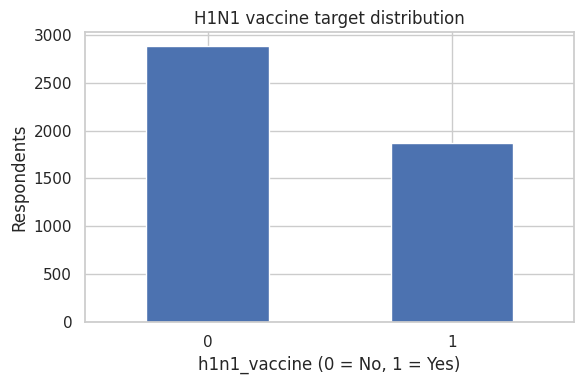

In [5]:
target_counts = train_raw[TARGET].value_counts().sort_index()
display(pd.DataFrame({
    "count": target_counts,
    "percentage": (target_counts / len(train_raw) * 100).round(2)
}))
ax = target_counts.plot(kind="bar", figsize=(6, 4), rot=0)
ax.set_title("H1N1 vaccine target distribution")
ax.set_xlabel("h1n1_vaccine (0 = No, 1 = Yes)")
ax.set_ylabel("Respondents")
plt.tight_layout()
plt.show()

### 7.2 Numeric feature distributions
Histograms help identify skew, unusual values and category-like numeric variables.

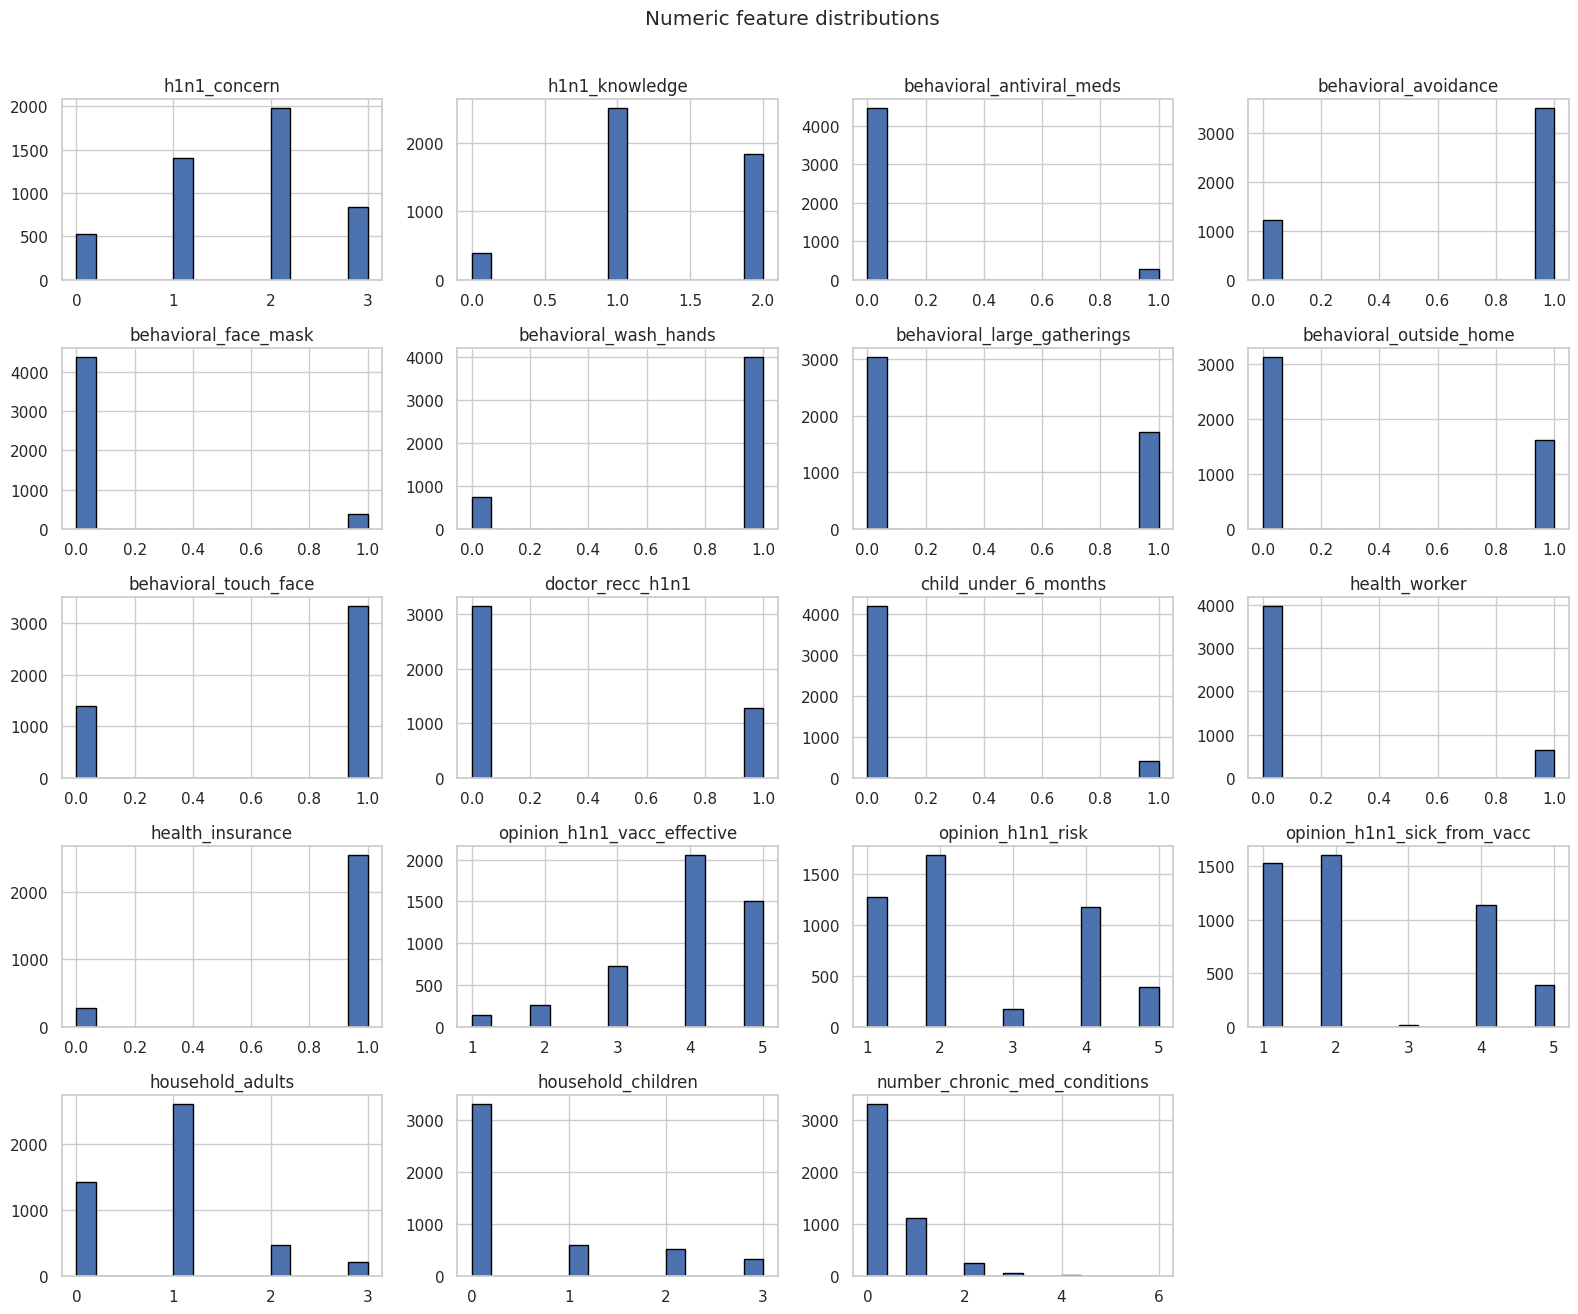

In [6]:
numeric_cols_all = train_raw.drop(columns=[ID_COL, TARGET]).select_dtypes(include=np.number).columns.tolist()
train_raw[numeric_cols_all].hist(figsize=(16, 13), bins=15, edgecolor="black")
plt.suptitle("Numeric feature distributions", y=1.01)
plt.tight_layout()
plt.show()

### 7.3 Categorical feature distributions
Show the most frequent levels for each categorical variable. The plots are descriptive, not causal.

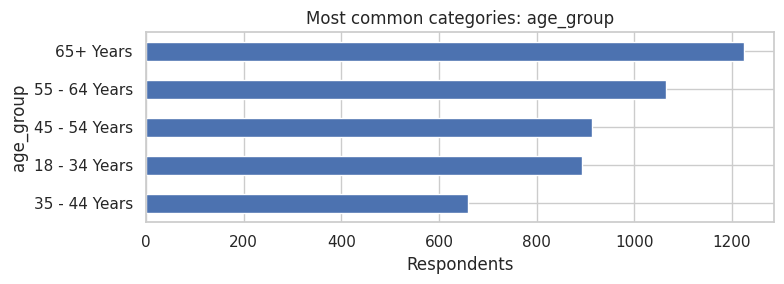

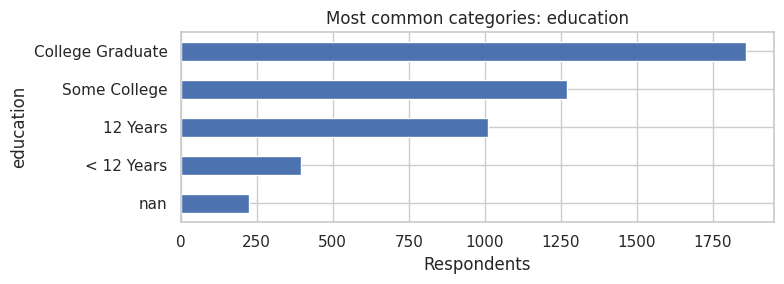

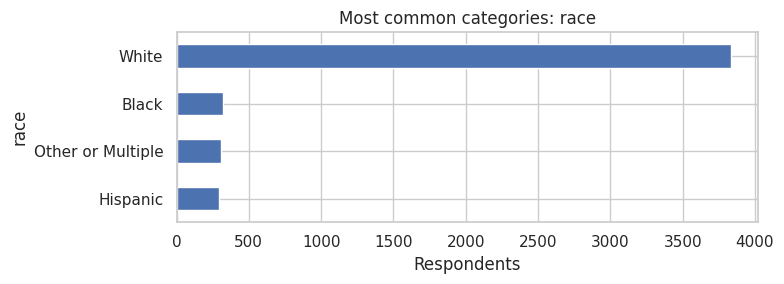

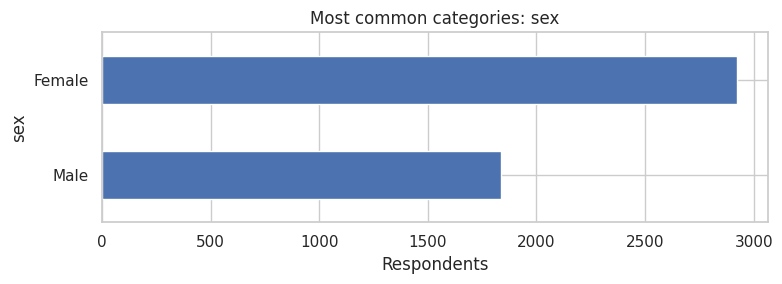

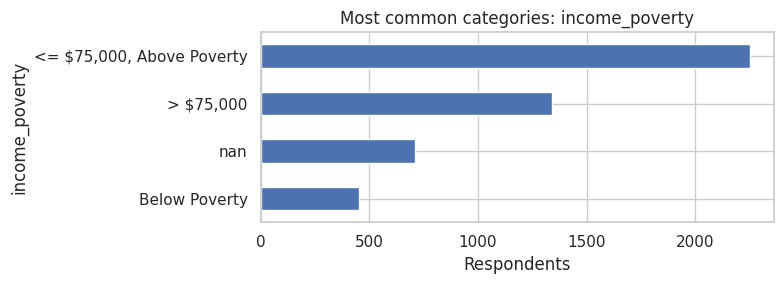

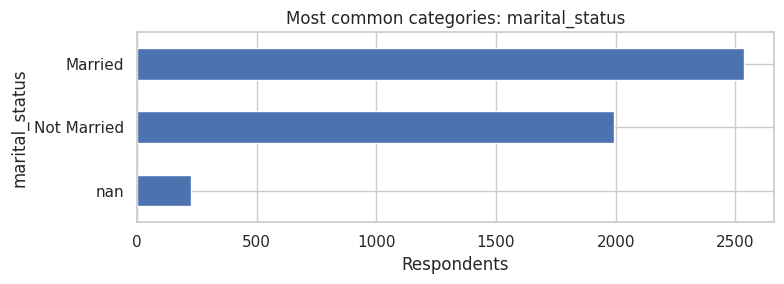

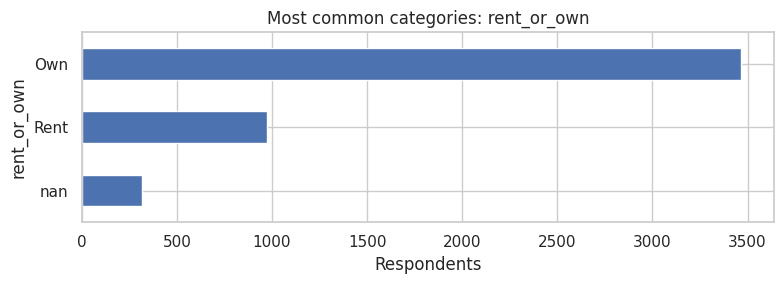

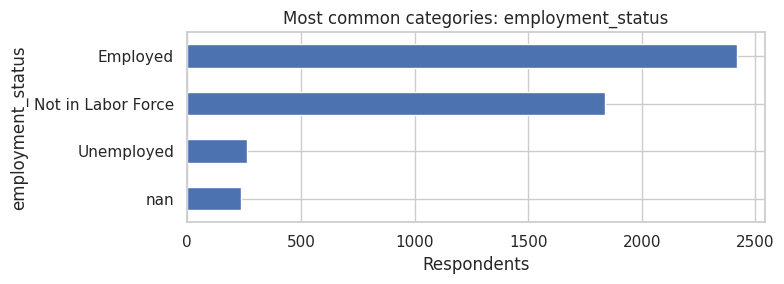

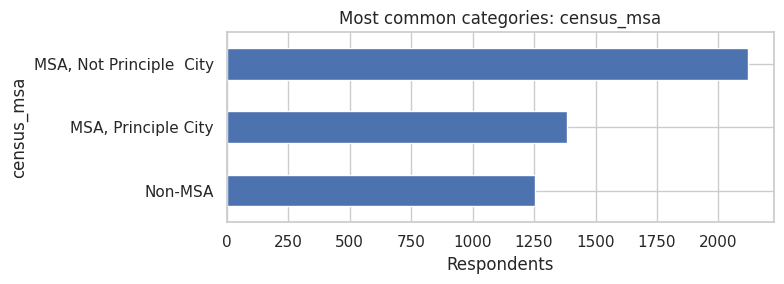

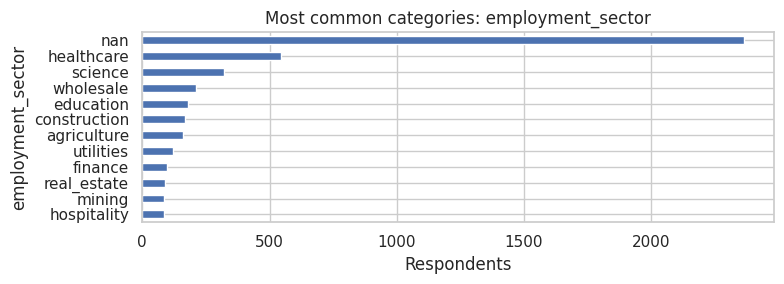

In [7]:
categorical_cols_all = train_raw.drop(columns=[ID_COL, TARGET]).select_dtypes(exclude=np.number).columns.tolist()
for col in categorical_cols_all:
    counts = train_raw[col].value_counts(dropna=False).head(12)
    plt.figure(figsize=(8, 3))
    counts.sort_values().plot(kind="barh")
    plt.title(f"Most common categories: {col}")
    plt.xlabel("Respondents")
    plt.tight_layout()
    plt.show()

### 7.4 Target rate by selected features
These group comparisons help communicate associations. Small groups and missing categories should be interpreted cautiously.

,mean,count
doctor_recc_h1n1,,
nan,18.2%,319
0.000000,27.9%,3149
1.000000,72.7%,1288


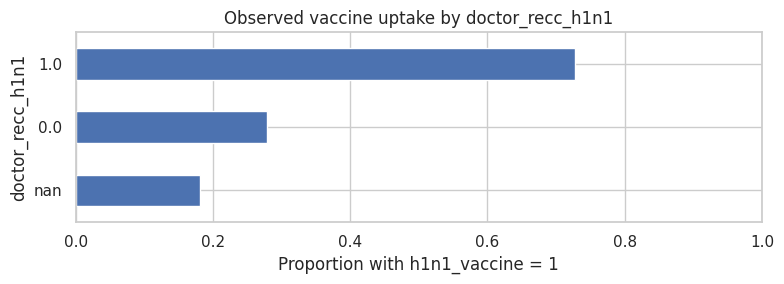

,mean,count
health_worker,,
nan,34.4%,131
0.000000,35.5%,3972
1.000000,64.3%,653


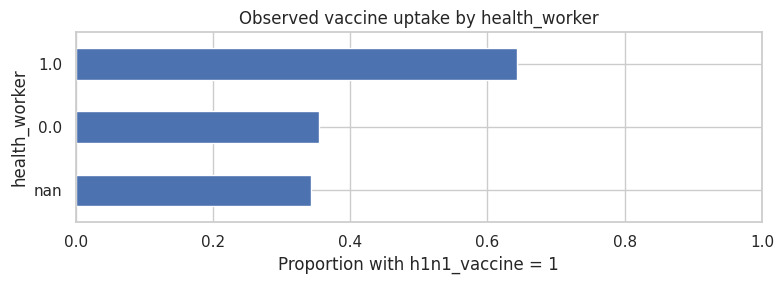

,mean,count
health_insurance,,
nan,23.6%,1925
0.000000,30.6%,278
1.000000,52.3%,2553


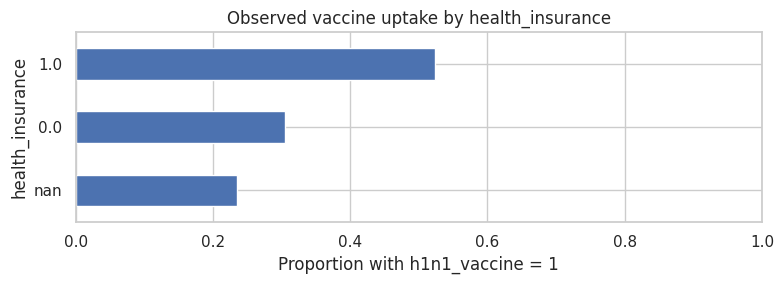

,mean,count
h1n1_concern,,
0.000000,29.5%,522
1.000000,32.5%,1406
nan,40.0%,15
2.000000,42.1%,1980
3.000000,50.9%,833


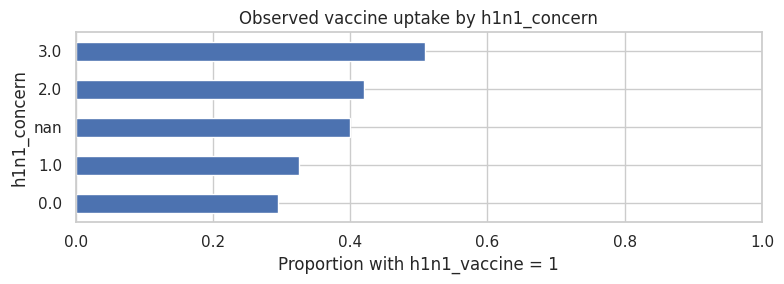

,mean,count
h1n1_knowledge,,
0.000000,27.3%,385
1.000000,34.7%,2510
nan,36.4%,22
2.000000,48.3%,1839


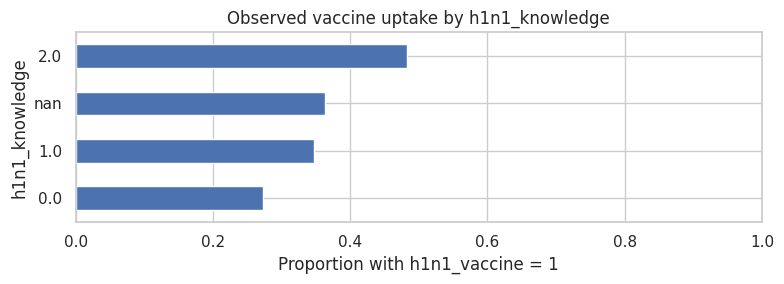

,mean,count
opinion_h1n1_vacc_effective,,
1.000000,10.8%,139
2.000000,12.7%,260
3.000000,22.3%,728
4.000000,33.9%,2057
nan,37.7%,69
5.000000,62.5%,1503


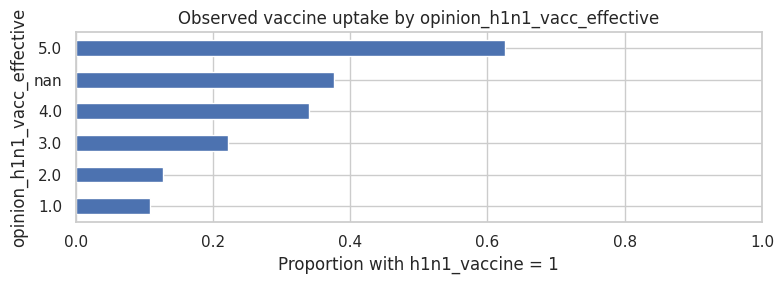

,mean,count
opinion_h1n1_risk,,
1.000000,19.9%,1274
2.000000,32.4%,1683
3.000000,36.0%,178
nan,39.1%,64
4.000000,61.1%,1171
5.000000,70.5%,386


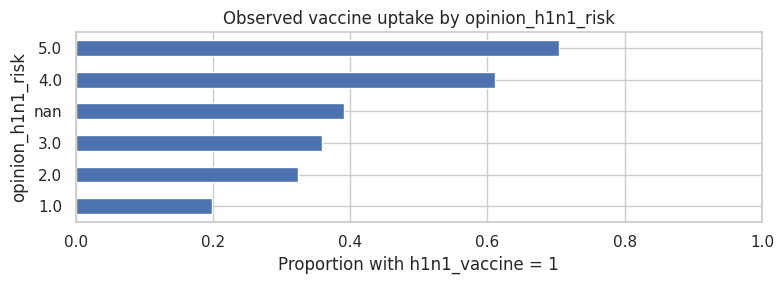

,mean,count
age_group,,
18 - 34 Years,36.5%,894
45 - 54 Years,36.6%,913
35 - 44 Years,39.6%,659
65+ Years,41.4%,1225
55 - 64 Years,41.9%,1065


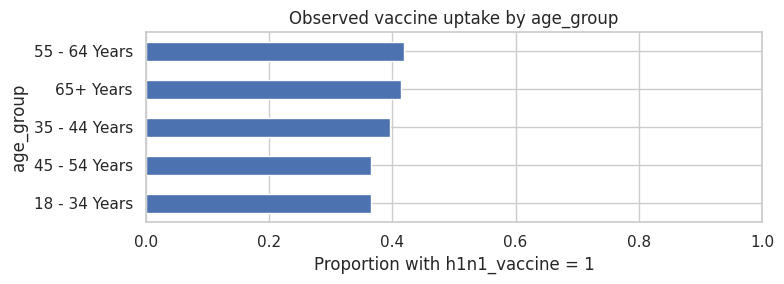

In [8]:
selected_eda_features = [
    "doctor_recc_h1n1", "health_worker", "health_insurance",
    "h1n1_concern", "h1n1_knowledge", "opinion_h1n1_vacc_effective",
    "opinion_h1n1_risk", "age_group"
]
for col in selected_eda_features:
    if col in train_raw.columns:
        rate = train_raw.groupby(col, dropna=False)[TARGET].agg(["mean", "count"]).sort_values("mean")
        display(rate.style.format({"mean": "{:.1%}"}).set_caption(f"Vaccination rate by {col}"))
        plt.figure(figsize=(8, 3))
        rate["mean"].plot(kind="barh")
        plt.title(f"Observed vaccine uptake by {col}")
        plt.xlabel("Proportion with h1n1_vaccine = 1")
        plt.xlim(0, 1)
        plt.tight_layout()
        plt.show()

## 8. Prepare features and a validation split

- `respondent_id` is excluded because it is a unique random identifier, not a meaningful health or behavioural predictor.
- `h1n1_vaccine` is the label and is excluded from the predictors.
- Dataset B supplies 29 predictor columns. The task description's “30 features” wording conflicts with its 29-item list and the actual CSVs; the notebook follows the CSV schema.
- Numeric columns use median imputation; scaling is used for logistic regression.
- Categorical columns use most-frequent imputation and one-hot encoding; unseen testing categories are safely ignored.
- The concern, knowledge and vaccine-opinion codes are ordered categories. They remain numeric in this preserved modelling workflow; scaling does not mean their response intervals are known to be equal.
- The split is stratified to preserve target proportions in both subsets. Preprocessing is fitted within each model pipeline, using only the training split during validation.


In [9]:
# Remove exact duplicate rows; retain the first occurrence.
train = train_raw.drop_duplicates().reset_index(drop=True).copy()
test = test_raw.copy()

X = train.drop(columns=[TARGET, ID_COL])
y = train[TARGET].astype(int)
X_test_final = test.drop(columns=[ID_COL])

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Predictor count:", X.shape[1])
print("Numeric predictors:", len(numeric_features))
print("Categorical predictors:", len(categorical_features))
print("Training split:", X_train.shape, "Validation split:", X_valid.shape)
print("Positive class rate - train:", round(y_train.mean(), 4),
      "validation:", round(y_valid.mean(), 4))

Predictor count: 29
Numeric predictors: 19
Categorical predictors: 10
Training split: (3804, 29) Validation split: (952, 29)
Positive class rate - train: 0.3941 validation: 0.3939


## 9. Train and compare classification models

We compare:
1. **Logistic Regression** – interpretable linear baseline.
2. **Random Forest** – bagged decision trees that can capture nonlinear patterns.
3. **Extra Trees** – highly randomised tree ensemble.
4. **Gradient Boosting** – sequentially builds trees to improve earlier errors.

All models use the same preprocessing pipeline. Model comparison is based primarily on ROC-AUC (ranking quality), with accuracy, precision, recall, F1, average precision and Brier score also reported. A lower Brier score indicates better probability calibration.

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2500, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=350, min_samples_leaf=2, class_weight="balanced_subsample",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=350, min_samples_leaf=2, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE)
}

fitted_models = {}
validation_probabilities = {}
rows = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    prob = pipe.predict_proba(X_valid)[:, 1]
    pred = (prob >= 0.50).astype(int)
    fitted_models[name] = pipe
    validation_probabilities[name] = prob
    rows.append({
        "model": name,
        "ROC_AUC": roc_auc_score(y_valid, prob),
        "Average_Precision": average_precision_score(y_valid, prob),
        "Accuracy_at_0.50": accuracy_score(y_valid, pred),
        "Precision_at_0.50": precision_score(y_valid, pred, zero_division=0),
        "Recall_at_0.50": recall_score(y_valid, pred, zero_division=0),
        "F1_at_0.50": f1_score(y_valid, pred, zero_division=0),
        "Brier_score": brier_score_loss(y_valid, prob)
    })

comparison = pd.DataFrame(rows).sort_values("ROC_AUC", ascending=False).reset_index(drop=True)
display(comparison.style.format({
    "ROC_AUC": "{:.4f}", "Average_Precision": "{:.4f}",
    "Accuracy_at_0.50": "{:.4f}", "Precision_at_0.50": "{:.4f}",
    "Recall_at_0.50": "{:.4f}", "F1_at_0.50": "{:.4f}", "Brier_score": "{:.4f}"
}))

,model,ROC_AUC,Average_Precision,Accuracy_at_0.50,Precision_at_0.50,Recall_at_0.50,F1_at_0.50,Brier_score
0,Logistic Regression,0.8163,0.7590,0.7416,0.6569,0.7200,0.6870,0.1739
1,Gradient Boosting,0.8086,0.7443,0.7637,0.7344,0.6267,0.6763,0.1699
2,Extra Trees,0.8035,0.7197,0.7500,0.6930,0.6560,0.6740,0.1749
3,Random Forest,0.7994,0.7195,0.7426,0.6766,0.6640,0.6703,0.1765


## 10. Select a model and choose a validation threshold

The model with the highest validation ROC-AUC is selected for the main probability predictions. The default 0.50 threshold is not necessarily best for every operational goal. We inspect F1 across thresholds to provide a transparent alternative. The threshold is selected using validation data only; do not interpret it as a universal medical or policy threshold.

Selected model by ROC-AUC: Logistic Regression
Best validation F1 threshold: 0.4


,threshold,precision,recall,f1
30,0.40,0.607214,0.808000,0.693364
41,0.51,0.669154,0.717333,0.692407
29,0.39,0.602386,0.808000,0.690205
42,0.52,0.676093,0.701333,0.688482
39,0.49,0.653846,0.725333,0.687737
35,0.45,0.629712,0.757333,0.687651
38,0.48,0.644860,0.736000,0.687422
40,0.50,0.656934,0.720000,0.687023
31,0.41,0.606122,0.792000,0.686705
24,0.34,0.572193,0.856000,0.685897


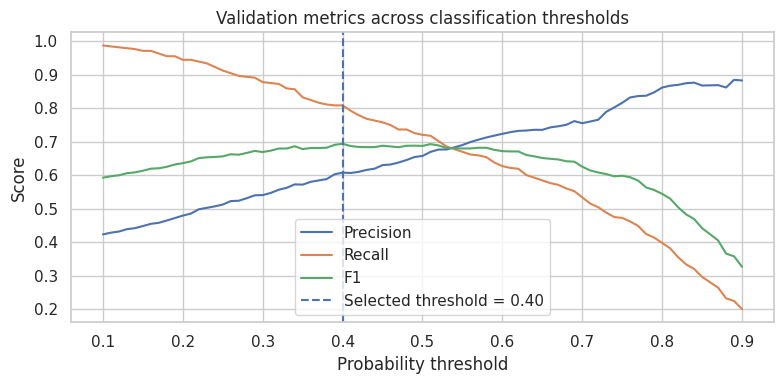

In [11]:
best_model_name = comparison.iloc[0]["model"]
best_model = fitted_models[best_model_name]
best_valid_prob = validation_probabilities[best_model_name]

threshold_grid = np.linspace(0.10, 0.90, 81)
threshold_rows = []
for threshold in threshold_grid:
    pred = (best_valid_prob >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_valid, pred, zero_division=0),
        "recall": recall_score(y_valid, pred, zero_division=0),
        "f1": f1_score(y_valid, pred, zero_division=0)
    })
threshold_table = pd.DataFrame(threshold_rows)
best_threshold = float(threshold_table.loc[threshold_table["f1"].idxmax(), "threshold"])

print("Selected model by ROC-AUC:", best_model_name)
print("Best validation F1 threshold:", round(best_threshold, 3))
display(threshold_table.sort_values("f1", ascending=False).head(10))

plt.figure(figsize=(8, 4))
plt.plot(threshold_table["threshold"], threshold_table["precision"], label="Precision")
plt.plot(threshold_table["threshold"], threshold_table["recall"], label="Recall")
plt.plot(threshold_table["threshold"], threshold_table["f1"], label="F1")
plt.axvline(best_threshold, linestyle="--", label=f"Selected threshold = {best_threshold:.2f}")
plt.xlabel("Probability threshold")
plt.ylabel("Score")
plt.title("Validation metrics across classification thresholds")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Detailed validation evaluation

The next outputs describe the selected model on held-out validation data. The classification report gives class-specific precision, recall and F1. The confusion matrix shows true/false positives and negatives. ROC and precision-recall curves show performance across thresholds.

Selected model: Logistic Regression

Classification report:
                precision    recall  f1-score   support

No vaccine (0)       0.84      0.66      0.74       577
   Vaccine (1)       0.61      0.81      0.69       375

      accuracy                           0.72       952
     macro avg       0.72      0.73      0.72       952
  weighted avg       0.75      0.72      0.72       952

ROC-AUC: 0.8163
Average precision: 0.759
Brier score: 0.1739


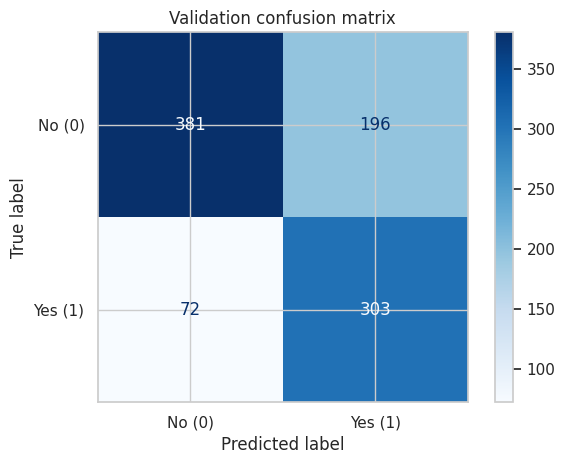

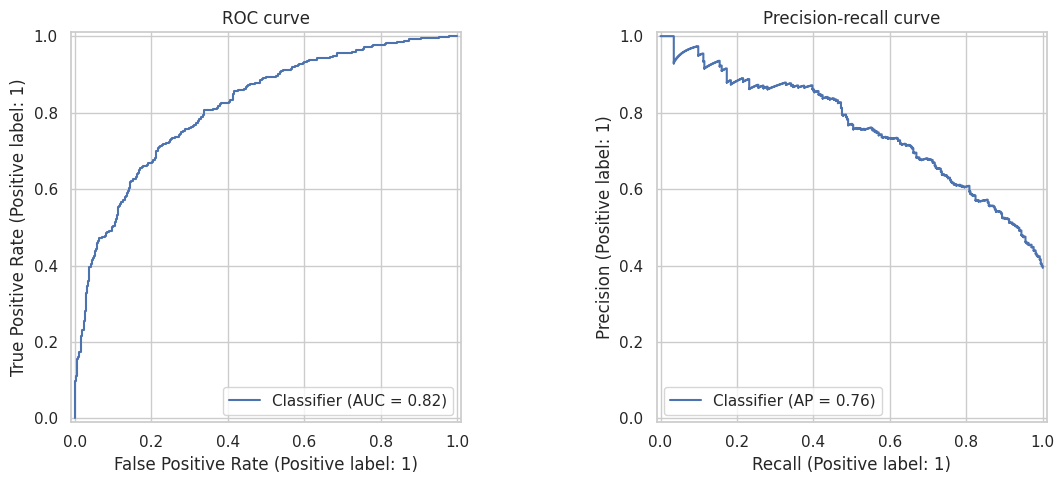

In [12]:
valid_pred = (best_valid_prob >= best_threshold).astype(int)
print("Selected model:", best_model_name)
print("\nClassification report:")
print(classification_report(y_valid, valid_pred, target_names=["No vaccine (0)", "Vaccine (1)"], zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_valid, best_valid_prob), 4))
print("Average precision:", round(average_precision_score(y_valid, best_valid_prob), 4))
print("Brier score:", round(brier_score_loss(y_valid, best_valid_prob), 4))

cm = confusion_matrix(y_valid, valid_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No (0)", "Yes (1)"]).plot(cmap="Blues", values_format="d")
plt.title("Validation confusion matrix")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_valid, best_valid_prob, ax=axes[0])
axes[0].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_valid, best_valid_prob, ax=axes[1])
axes[1].set_title("Precision-recall curve")
plt.tight_layout()
plt.show()

## 12. Model interpretation with permutation importance

Permutation importance measures how much the validation ROC-AUC falls when one original input column is shuffled. Larger positive values indicate that the model relies more on that feature for validation ranking. This is an association/model-dependence measure, not proof of causation.

,feature,importance_mean,importance_std
9,doctor_recc_h1n1,0.094282,0.009499
13,opinion_h1n1_vacc_effective,0.052382,0.008481
14,opinion_h1n1_risk,0.030952,0.008727
11,health_worker,0.009936,0.001302
16,age_group,0.004935,0.001734
27,employment_sector,0.004607,0.001913
18,race,0.004372,0.001348
17,education,0.004117,0.001326
19,sex,0.003074,0.000649
6,behavioral_large_gatherings,0.002038,0.001868


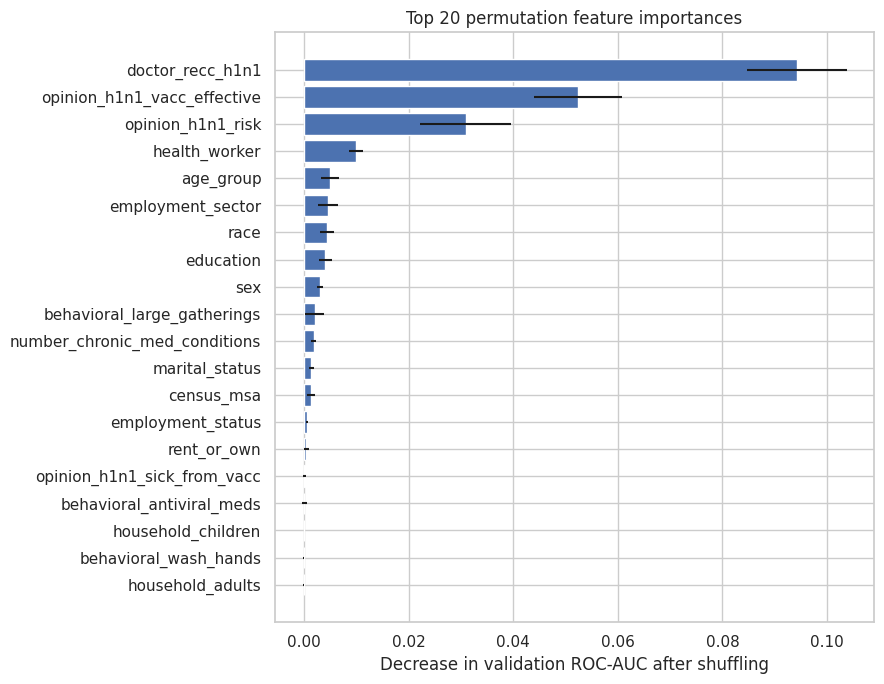

In [13]:
perm = permutation_importance(
    best_model, X_valid, y_valid, scoring="roc_auc",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)
importance = pd.DataFrame({
    "feature": X_valid.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)
display(importance.head(20))

plt.figure(figsize=(9, 7))
top_imp = importance.head(20).sort_values("importance_mean")
plt.barh(top_imp["feature"], top_imp["importance_mean"], xerr=top_imp["importance_std"])
plt.xlabel("Decrease in validation ROC-AUC after shuffling")
plt.title("Top 20 permutation feature importances")
plt.tight_layout()
plt.show()

### 13.0 Optional external hospitalisation-risk scenario inputs (not supplied in Dataset B)

**What the task information actually supplies:** vaccine cost ($500), hospitalisation cost ($25,000), and the vaccine-uptake target `h1n1_vaccine`.

The Dataset B Information text does **not** supply a hospitalisation outcome, an individual hospitalisation probability, age-specific hospitalisation multipliers, a chronic-condition risk coefficient, or vaccine effectiveness. Therefore, none of those quantities can be learned or validated from the Dataset B files.

The existing optional scenario below is retained so the earlier analysis is not lost. It uses external published context and simplifying assumptions only. Treat these values as illustrative inputs for sensitivity analysis, **not as official Dataset B parameters, clinical estimates for a particular respondent, or predictions from the machine-learning model**.

The previously used aggregate comparison (274,304 hospitalisations divided by 60.8 million estimated cases, approximately 0.451%) is an aggregate hospitalisations-to-estimated-cases ratio. It is not an individual risk estimate and is not specifically the risk for an unvaccinated healthy 35–44-year-old. The age multipliers, chronic-condition coefficient and vaccine-effectiveness values below are judgement-based scenario assumptions and should be changed only if an appropriate source or task instruction supplies validated values.

**Retained illustrative inputs (external assumptions):**
- `base_risk = 0.00451` (0.451% proxy), with sensitivity range `[0.0022, 0.0093]`.
- Age multipliers: 18–34 `0.80`; 35–44 `1.00`; 45–54 `1.10`; 55–64 `1.40`; 65+ `1.30`.
- `chronic_k = 0.80`, with sensitivity range `[0.30, 1.50]`.
- `vaccine_effectiveness = 0.60`, with sensitivity range `[0.15, 0.80]`.

These are not coefficients estimated from the Dataset B respondent data. The task sheet's two costs can be used in the break-even calculations independently of these optional assumptions.


In [14]:
# External scenario inputs for the individual hospitalisation-risk exercise.
# These are not estimated from Dataset B because it has no hospitalisation label.
cdc_estimated_cases = 60_800_000
cdc_estimated_hospitalisations = 274_304
cdc_hosp_per_estimated_case = cdc_estimated_hospitalisations / cdc_estimated_cases

HOSPITALISATION_RISK = {
    "base_risk": 0.00451,
    "base_risk_range": [0.0022, 0.0093],
    "age_mult": {
        "18-34": 0.80,
        "35-44": 1.00,
        "45-54": 1.10,
        "55-64": 1.40,
        "65+": 1.30
    },
    "chronic_k": 0.80,
    "chronic_k_range": [0.30, 1.50],
    "vacc_eff": 0.60,
    "vacc_eff_range": [0.15, 0.80]
}

print(f"CDC/Shrestha aggregate hospitalisations per estimated case: {cdc_hosp_per_estimated_case:.5%}")
print("Exercise base_risk proxy:", HOSPITALISATION_RISK["base_risk"])
print("Note: aggregate case rate is used as a proxy, not a validated healthy 35–44 per-infection baseline.")

CDC/Shrestha aggregate hospitalisations per estimated case: 0.45116%
Exercise base_risk proxy: 0.00451
Note: aggregate case rate is used as a proxy, not a validated healthy 35–44 per-infection baseline.


## 13. Cost model and decision analysis

### 13.1 What the Dataset B information and data can and cannot establish

The Dataset B Information text supplies two cost values:
- H1N1 vaccine: **$500** per dose.
- Hospitalisation for H1N1 flu: **$25,000** per hospitalisation.

The training label is `h1n1_vaccine`, which records vaccine uptake. The supplied data has no column for infection, hospitalisation, individual hospitalisation probability, or vaccine effectiveness. Consequently:
- The classifier estimates **vaccine uptake probability**, not infection or hospitalisation probability.
- The supplied data alone cannot estimate the town's actual expected hospitalisation cost or the clinical benefit of vaccinating a particular person.
- Any hospitalisation-risk or vaccine-effectiveness values used below are explicitly hypothetical/external scenario assumptions, not facts supplied by Dataset B.

### 13.2 Break-even calculation using the supplied costs

Let:
- vaccine cost = $500 per dose (from Dataset B Information);
- hospitalisation cost = $25,000 per hospitalisation (from Dataset B Information);
- `p_H` = hypothetical probability of hospitalisation without vaccination;
- `e` = assumed proportionate reduction in hospitalisation risk due to vaccination, between 0 and 1 (not supplied in Dataset B).

Expected cost if **not vaccinated**: `p_H × 25,000`.

Expected cost if **vaccinated**: `500 + p_H × (1-e) × 25,000`.

Vaccination has lower expected cost under this simplified model when:
`500 < p_H × e × 25,000`, or `p_H > 500/(25,000e)`.

If we assume 100% prevention purely for illustration (`e = 1`), the break-even hospitalisation probability is 2%. This is a mathematical scenario derived from the two task-sheet costs, not an estimated probability from the supplied data. If effectiveness is lower, the break-even risk is higher.


In [15]:
VACCINE_COST = 500.0
HOSPITALISATION_COST = 25000.0

effectiveness_scenarios = [1.00, 0.80, 0.50]
break_even_rows = []
for effectiveness in effectiveness_scenarios:
    break_even_rows.append({
        "assumed_reduction_in_hospitalisation_risk": effectiveness,
        "break_even_hospitalisation_probability": VACCINE_COST / (HOSPITALISATION_COST * effectiveness)
    })
break_even = pd.DataFrame(break_even_rows)
display(break_even.style.format({
    "assumed_reduction_in_hospitalisation_risk": "{:.0%}",
    "break_even_hospitalisation_probability": "{:.2%}"
}))

,assumed_reduction_in_hospitalisation_risk,break_even_hospitalisation_probability
0,100%,2.00%
1,80%,2.50%
2,50%,4.00%


### 13.3 Town-level scenario comparison (illustrative only)

The task assumes **100% probability of infection**, so the hospitalisation probability used below is conditional on infection and is not multiplied by an infection probability. Dataset B contains no hospitalisation outcome, so the risk inputs remain illustrative assumptions, not learned predictions. The following simple scenarios compare no vaccination with vaccinating everyone; they are sensitivity analysis only, not the final individual allocation strategy.

In [16]:
town_size = len(train_raw)  # Demonstration only; replace with actual town population if known.
scenario_risks = [0.005, 0.01, 0.02, 0.05, 0.10]
assumed_effectiveness = HOSPITALISATION_RISK["vacc_eff"]

scenario_rows = []
for risk in scenario_risks:
    no_vaccine_cost = town_size * risk * HOSPITALISATION_COST
    all_vaccinated_cost = town_size * (
        VACCINE_COST + risk * (1 - assumed_effectiveness) * HOSPITALISATION_COST
    )
    scenario_rows.append({
        "hypothetical_hospitalisation_risk_if_unvaccinated": risk,
        "expected_cost_no_vaccination_USD": no_vaccine_cost,
        "expected_cost_all_vaccinated_USD": all_vaccinated_cost,
        "lower_cost_option_under_assumptions": (
            "Vaccinate" if all_vaccinated_cost < no_vaccine_cost else "Do not vaccinate"
        )
    })
scenario_costs = pd.DataFrame(scenario_rows)
display(scenario_costs.style.format({
    "hypothetical_hospitalisation_risk_if_unvaccinated": "{:.1%}",
    "expected_cost_no_vaccination_USD": "${:,.0f}",
    "expected_cost_all_vaccinated_USD": "${:,.0f}"
}))
print("Illustrative town size (training rows):", town_size)
print("Assumed vaccine effectiveness:", assumed_effectiveness)

,hypothetical_hospitalisation_risk_if_unvaccinated,expected_cost_no_vaccination_USD,expected_cost_all_vaccinated_USD,lower_cost_option_under_assumptions
0,0.5%,"$594,500","$2,615,800",Do not vaccinate
1,1.0%,"$1,189,000","$2,853,600",Do not vaccinate
2,2.0%,"$2,378,000","$3,329,200",Do not vaccinate
3,5.0%,"$5,945,000","$4,756,000",Vaccinate
4,10.0%,"$11,890,000","$7,134,000",Vaccinate


Illustrative town size (training rows): 4756
Assumed vaccine effectiveness: 0.6


### 13.4 Operational use of vaccine-uptake predictions

The model estimates the probability that each respondent will accept/use a vaccine, using historical uptake as a proxy for willingness. Because doses are delivered to individual homes and unused doses are wasted, the decision must be made respondent by respondent. The target does not directly ask current consent, so predictions should be treated as estimates, not confirmed consent. The task also says a person who wants a vaccine but cannot receive one must be compensated by the vaccine cost ($500). The individual decision calculation below explicitly includes this expected compensation.

In [17]:
# Demand-planning summary using the validation probabilities.
print("Mean predicted uptake probability on validation:", round(float(best_valid_prob.mean()), 4))
print("Observed uptake rate in validation:", round(float(y_valid.mean()), 4))
print("Estimated expected accepters in validation sample:",
      round(float(best_valid_prob.sum()), 1), "out of", len(best_valid_prob))

Mean predicted uptake probability on validation: 0.4672
Observed uptake rate in validation: 0.3939
Estimated expected accepters in validation sample: 444.8 out of 952


## 14. Train the final model on all labelled training data

After model selection and validation, refit the selected model on all available labelled Dataset B rows. The preprocessing steps are refitted on the full training data only. The testing set remains unseen during model selection.

In [18]:
final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", models[best_model_name])
])
final_model.fit(X, y)

test_probabilities = final_model.predict_proba(X_test_final)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)

print("Final model:", best_model_name)
print("Test rows scored:", len(test_probabilities))
print("Mean predicted uptake probability:", round(float(test_probabilities.mean()), 4))
print("Predicted positive count at selected threshold:", int(test_predictions.sum()))

Final model: Logistic Regression
Test rows scored: 4749
Mean predicted uptake probability: 0.4693
Predicted positive count at selected threshold: 2459


## 15. Individual vaccine allocation and total expected cost (target metric)

This is the main decision-analysis output. It combines the model's respondent-level vaccine-uptake probability with a transparent, editable hospitalisation-risk scenario. The task's 100% infection assumption means each respondent is treated as infected; only the probability of hospitalisation is estimated. **Dataset B has no hospitalisation labels**, so individual hospitalisation risks cannot be trained or validated from these files. The baseline risk, age multipliers, chronic-condition multiplier and vaccine effectiveness below are assumptions retained for sensitivity analysis, not official task-sheet values or clinical advice.

For each respondent, compare:
- **Send a dose:** pay $500 whether accepted or wasted; hospitalisation risk is reduced only with probability `p_accept`.
- **Do not send a dose:** pay expected compensation of `$500 × p_accept` for willing people who cannot receive a vaccine; hospitalisation risk remains unvaccinated.

Choose the lower expected total cost for each respondent. This is a simplified expected-cost rule and assumes the town can make individual decisions without a fixed supply cap. If the organiser specifies a supply limit or a different interpretation of compensation, update the rule.

In [19]:
# Explicit editable assumptions. These are not estimated from Dataset B.
BASE_HOSP_RISK = HOSPITALISATION_RISK["base_risk"]
CHRONIC_RISK_MULTIPLIER_PER_CONDITION = HOSPITALISATION_RISK["chronic_k"]
VACCINE_EFFECTIVENESS = HOSPITALISATION_RISK["vacc_eff"]

# Map the dataset's age bands to transparent relative-risk multipliers.
age_multiplier_map = {
    "18 - 34 Years": HOSPITALISATION_RISK["age_mult"]["18-34"],
    "35 - 44 Years": HOSPITALISATION_RISK["age_mult"]["35-44"],
    "45 - 54 Years": HOSPITALISATION_RISK["age_mult"]["45-54"],
    "55 - 64 Years": HOSPITALISATION_RISK["age_mult"]["55-64"],
    "65+ Years": HOSPITALISATION_RISK["age_mult"]["65+"],
}

individual_decisions = test[[ID_COL, "age_group", "number_chronic_med_conditions"]].copy()
individual_decisions["p_accept_vaccine"] = test_probabilities
individual_decisions["age_risk_multiplier"] = individual_decisions["age_group"].map(age_multiplier_map).fillna(1.0)
individual_decisions["chronic_conditions"] = pd.to_numeric(
    individual_decisions["number_chronic_med_conditions"], errors="coerce"
).fillna(0).clip(lower=0)

# Multiplicative risk adjustment is a modelling assumption; cap probability at 1.
individual_decisions["p_hospitalisation_if_unvaccinated"] = (
    BASE_HOSP_RISK
    * individual_decisions["age_risk_multiplier"]
    * (1 + CHRONIC_RISK_MULTIPLIER_PER_CONDITION * individual_decisions["chronic_conditions"])
).clip(upper=1.0)
individual_decisions["p_hospitalisation_if_vaccinated"] = (
    individual_decisions["p_hospitalisation_if_unvaccinated"] * (1 - VACCINE_EFFECTIVENESS)
)

p = individual_decisions["p_accept_vaccine"]
r0 = individual_decisions["p_hospitalisation_if_unvaccinated"]
r1 = individual_decisions["p_hospitalisation_if_vaccinated"]

# Expected cost if no dose is sent: expected compensation for willing people + hospitalisations.
individual_decisions["expected_cost_no_dose_USD"] = (
    p * VACCINE_COST + r0 * HOSPITALISATION_COST
)
# Expected cost if a dose is sent: dose cost even if refused/wasted + expected hospitalisations.
individual_decisions["expected_cost_send_dose_USD"] = (
    VACCINE_COST + (p * r1 + (1 - p) * r0) * HOSPITALISATION_COST
)
individual_decisions["send_dose"] = (
    individual_decisions["expected_cost_send_dose_USD"]
    < individual_decisions["expected_cost_no_dose_USD"]
)
individual_decisions["chosen_expected_cost_USD"] = np.where(
    individual_decisions["send_dose"],
    individual_decisions["expected_cost_send_dose_USD"],
    individual_decisions["expected_cost_no_dose_USD"]
)

# Summarise expected cost components under the selected respondent-level decisions.
individual_decisions["expected_vaccine_or_compensation_USD"] = np.where(
    individual_decisions["send_dose"],
    VACCINE_COST,
    p * VACCINE_COST
)
individual_decisions["expected_hospitalisation_cost_USD"] = np.where(
    individual_decisions["send_dose"],
    (p * r1 + (1 - p) * r0) * HOSPITALISATION_COST,
    r0 * HOSPITALISATION_COST
)

print("Test respondents:", len(individual_decisions))
print("Doses to send under assumptions:", int(individual_decisions["send_dose"].sum()))
print("Expected vaccine/compensation cost: $", round(individual_decisions["expected_vaccine_or_compensation_USD"].sum(), 2))
print("Expected hospitalisation cost: $", round(individual_decisions["expected_hospitalisation_cost_USD"].sum(), 2))
print("Total expected town cost for these test respondents: $", round(individual_decisions["chosen_expected_cost_USD"].sum(), 2))
display(individual_decisions.head(10))

# Save respondent-level decisions so the town knows exactly whom the model recommends.
individual_decisions.to_csv("h1n1_individual_vaccine_decisions.csv", index=False)
print("Saved h1n1_individual_vaccine_decisions.csv")

Test respondents: 4749
Doses to send under assumptions: 802
Expected vaccine/compensation cost: $ 1155369.64
Expected hospitalisation cost: $ 712371.65
Total expected town cost for these test respondents: $ 1867741.29


,respondent_id,age_group,number_chronic_med_conditions,p_accept_vaccine,age_risk_multiplier,chronic_conditions,p_hospitalisation_if_unvaccinated,p_hospitalisation_if_vaccinated,expected_cost_no_dose_USD,expected_cost_send_dose_USD,send_dose,chosen_expected_cost_USD,expected_vaccine_or_compensation_USD,expected_hospitalisation_cost_USD
0,4757,65+ Years,0,0.274113,1.3,0,0.005863,0.002345,283.631582,622.468118,False,283.631582,137.056582,146.575000
1,4758,65+ Years,0,0.095408,1.3,0,0.005863,0.002345,194.278839,638.184372,False,194.278839,47.703839,146.575000
2,4759,65+ Years,0,0.124541,1.3,0,0.005863,0.002345,208.845260,635.622284,False,208.845260,62.270260,146.575000
3,4760,55 - 64 Years,1,0.265653,1.4,1,0.011365,0.004546,416.956656,738.841955,False,416.956656,132.826656,284.130000
4,4761,35 - 44 Years,0,0.140200,1.0,0,0.004510,0.001804,182.850040,603.265465,False,182.850040,70.100040,112.750000
5,4762,55 - 64 Years,0,0.733324,1.4,0,0.006314,0.002526,524.511990,588.396886,False,524.511990,366.661990,157.850000
6,4763,18 - 34 Years,0,0.627552,0.8,0,0.003608,0.001443,403.976189,556.236865,False,403.976189,313.776189,90.200000
7,4764,45 - 54 Years,3,0.927296,1.1,3,0.016867,0.006747,885.332980,687.068922,True,687.068922,500.000000,187.068922
8,4765,65+ Years,0,0.893896,1.3,0,0.005863,0.002345,593.523029,567.961311,True,567.961311,500.000000,67.961311
9,4766,55 - 64 Years,0,0.468814,1.4,0,0.006314,0.002526,392.256768,613.448670,False,392.256768,234.406768,157.850000


Saved h1n1_individual_vaccine_decisions.csv


## 16. Create the Dataset B submission file

The output currently contains:
- `respondent_id`: copied in the original testing-row order;
- `h1n1_vaccine`: predicted probability of class 1 (vaccine uptake).

The testing file contains 4,749 respondents, so the generated file has 4,749 prediction rows. Probabilities are retained by this notebook because they preserve confidence information and are a common format for binary prediction tasks. **The official submission format has not yet been independently confirmed from an official Dataset B example file.** If the organiser requires hard 0/1 labels, a different column name, a different filename, or a particular row order, follow that specification. Do not use the Dataset A example file to infer Dataset B's target column or submission rules.


In [20]:
submission = pd.DataFrame({
    ID_COL: test[ID_COL].values,
    TARGET: test_probabilities
})
assert submission.shape == (len(test), 2)
assert submission[ID_COL].equals(test[ID_COL].reset_index(drop=True))
assert submission[TARGET].between(0, 1).all()
assert submission[ID_COL].is_unique

submission.to_csv("dataset_B_submission.csv", index=False)
display(submission.head(10))
print("Saved dataset_B_submission.csv")

,respondent_id,h1n1_vaccine
0,4757,0.274113
1,4758,0.095408
2,4759,0.124541
3,4760,0.265653
4,4761,0.140200
5,4762,0.733324
6,4763,0.627552
7,4764,0.927296
8,4765,0.893896
9,4766,0.468814


Saved dataset_B_submission.csv


## 17. Save additional audit outputs

Save the validation model comparison, validation predictions and feature importance so the team can report results transparently. These are analysis outputs, not competition submissions.

In [21]:
validation_output = pd.DataFrame({
    ID_COL: train.loc[X_valid.index, ID_COL].values,
    "actual_h1n1_vaccine": y_valid.values,
    "predicted_probability": best_valid_prob,
    "predicted_class": valid_pred
})
comparison.to_csv("model_comparison.csv", index=False)
importance.to_csv("permutation_feature_importance.csv", index=False)
validation_output.to_csv("validation_predictions.csv", index=False)
print("Saved: model_comparison.csv, permutation_feature_importance.csv, validation_predictions.csv")

Saved: model_comparison.csv, permutation_feature_importance.csv, validation_predictions.csv


## 18. Limitations and further work

- No hospitalisation or infection outcome is supplied; a separate labelled health-outcome dataset is required to train a hospitalisation-risk model.
- No vaccine-effectiveness value is supplied; cost scenarios therefore require explicit assumptions.
- Validation results are from one random hold-out split. For stronger evidence, use repeated stratified cross-validation and an independent external test set.
- The dataset may contain historical patterns that do not generalise to a different population, time period or disease.
- Check subgroup performance and calibration before any real-world use.
- If the competition specifies a required file name, probability format, metric or decision threshold, follow that specification over the illustrative defaults in this notebook.